In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv(
    "../dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

# Display first 5 messages
display(df.head())

# Dataset information
print("Dataset Shape:", df.shape)

print("\nClass Distribution:")
print(df["label"].value_counts())

print("\nMissing Values:")
print(df.isnull().sum())

Matplotlib is building the font cache; this may take a moment.


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Dataset Shape: (5572, 2)

Class Distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Missing Values:
label      0
message    0
dtype: int64


In [3]:
# Check duplicate records

print("Total Records:", len(df))

# Exact duplicate rows
exact_duplicates = df.duplicated().sum()

# Duplicate SMS messages
duplicate_messages = df.duplicated(
    subset=["message"]
).sum()

# Messages having conflicting labels
conflicts = df.groupby("message")["label"].nunique()
conflicting_messages = conflicts[conflicts > 1]

print("\nExact Duplicate Rows:", exact_duplicates)
print("Duplicate Messages:", duplicate_messages)
print("Conflicting Labels:", len(conflicting_messages))

# Remove duplicate messages safely
if len(conflicting_messages) == 0:
    df_clean = df.drop_duplicates(
        subset=["message"],
        keep="first"
    ).copy()
else:
    raise ValueError("Conflicting labels found. Review them before deduplication.")

print("\nRecords After Deduplication:", len(df_clean))
print("Duplicates Removed:", len(df) - len(df_clean))

Total Records: 5572

Exact Duplicate Rows: 403
Duplicate Messages: 403
Conflicting Labels: 0

Records After Deduplication: 5169
Duplicates Removed: 403


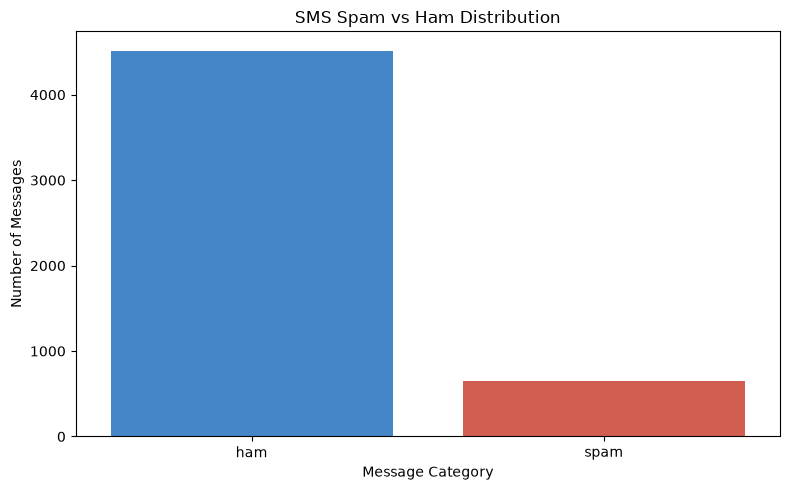

In [4]:
# Spam vs Ham Distribution Graph

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x="label",
    hue="label",
    order=["ham", "spam"],
    palette=["#2E86DE", "#E74C3C"],
    legend=False
)

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")

plt.tight_layout()
plt.show()

In [5]:

import re

# Common SMS abbreviations
short_forms = {
    "u": "you",
    "ur": "your",
    "r": "are",
    "pls": "please",
    "plz": "please",
    "msg": "message",
    "txt": "text",
    "gr8": "great",
    "thx": "thanks",
    "b4": "before",
    "asap": "as soon as possible"
}

def clean_sms(text):
    text = str(text).lower()

    # Replace URLs
    text = re.sub(
        r"http\S+|www\.\S+",
        " urltoken ",
        text
    )

    # Replace email addresses
    text = re.sub(
        r"\b[\w.+-]+@[\w.-]+\.[a-z]{2,}\b",
        " emailtoken ",
        text
    )

    # Replace currency amounts
    text = re.sub(
        r"(?:₹|rs\.?|inr|\$|£)\s*\d+(?:[.,]\d+)?",
        " moneytoken ",
        text
    )

    # Replace Indian mobile numbers
    text = re.sub(
        r"(?<!\w)(?:\+?91[\s-]?)?[6-9]\d{9}(?!\w)",
        " phonetoken ",
        text
    )

    # Replace long numeric sequences
    text = re.sub(
        r"\b\d{7,}\b",
        " numbertoken ",
        text
    )

    # Replace remaining numbers
    text = re.sub(
        r"\d+(?:[.,]\d+)?",
        " numbertoken ",
        text
    )

    # Expand common SMS short forms
    words = text.split()
    words = [short_forms.get(word, word) for word in words]
    text = " ".join(words)

    # Remove special characters
    text = re.sub(r"[^\w\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Apply preprocessing
df_clean["clean_message"] = df_clean["message"].apply(clean_sms)

print("Text preprocessing completed!")

# Compare original and cleaned messages
display(
    df_clean[["message", "clean_message"]].head(15)
)


Text preprocessing completed!


,message,clean_message
0,"Go until jurong point, crazy.. Available only ...",go until jurong point crazy available only in ...
1,Ok lar... Joking wif u oni...,ok lar joking wif you oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in numbertoken a wkly comp to win f...
3,U dun say so early hor... U c already then say...,you dun say so early hor you c already then say
4,"Nah I don't think he goes to usf, he lives aro...",nah i don t think he goes to usf he lives arou...
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it s been numbertoke...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me t...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request melle melle oru minnaminun...
8,WINNER!! As a valued network customer you have...,winner as a valued network customer you have b...
9,Had your mobile 11 months or more? U R entitle...,had your mobile numbertoken months or more you...


In [6]:
from sklearn.model_selection import train_test_split

# Features and target
X = df_clean["clean_message"]
y = df_clean["label"]

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display results
print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

print("\nTrain-Test Split Completed!")

Training Samples: 4135
Testing Samples: 1034

Training Class Distribution:
label
ham     3613
spam     522
Name: count, dtype: int64

Testing Class Distribution:
label
ham     903
spam    131
Name: count, dtype: int64

Train-Test Split Completed!


In [7]:

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# 1. Bag of Words
bow_vectorizer = CountVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)


# 2. TF-IDF
tfidf_vectorizer = TfidfVectorizer(
    max_features=15000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)


# Display results
print("FEATURE EXTRACTION COMPLETED")

print("\nBag of Words:")
print("Training Shape:", X_train_bow.shape)
print("Testing Shape:", X_test_bow.shape)
print("Vocabulary Size:", len(bow_vectorizer.vocabulary_))

print("\nTF-IDF:")
print("Training Shape:", X_train_tfidf.shape)
print("Testing Shape:", X_test_tfidf.shape)
print("Vocabulary Size:", len(tfidf_vectorizer.vocabulary_))


FEATURE EXTRACTION COMPLETED

Bag of Words:
Training Shape: (4135, 10069)
Testing Shape: (1034, 10069)
Vocabulary Size: 10069

TF-IDF:
Training Shape: (4135, 10069)
Testing Shape: (1034, 10069)
Vocabulary Size: 10069


In [8]:

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Models
models = {
    "Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        random_state=42
    ),
    "Linear SVM": LinearSVC(
        random_state=42,
        max_iter=5000
    )
}

# Feature datasets
feature_sets = {
    "BoW": (X_train_bow, X_test_bow),
    "TF-IDF": (X_train_tfidf, X_test_tfidf)
}

results = []
trained_models = {}

# Train and evaluate all 6 experiments
for feature_name, (Xtr, Xte) in feature_sets.items():

    for model_name, model in models.items():

        print(f"Training {model_name} with {feature_name}...")

        model.fit(Xtr, y_train)

        predictions = model.predict(Xte)

        results.append({
            "Model": model_name,
            "Features": feature_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, pos_label="spam"
            ),
            "Recall": recall_score(
                y_test, predictions, pos_label="spam"
            ),
            "F1 Score": f1_score(
                y_test, predictions, pos_label="spam"
            )
        })

        trained_models[f"{model_name}_{feature_name}"] = model

# Comparison table
results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        by="F1 Score",
        ascending=False
    ).round(4)
)

print("All 6 model experiments completed!")


Training Naive Bayes with BoW...
Training Logistic Regression with BoW...
Training Linear SVM with BoW...
Training Naive Bayes with TF-IDF...
Training Logistic Regression with TF-IDF...
Training Linear SVM with TF-IDF...


,Model,Features,Accuracy,Precision,Recall,F1 Score
0,Naive Bayes,BoW,0.9884,0.9685,0.9389,0.9535
2,Linear SVM,BoW,0.9874,0.9917,0.9084,0.9482
5,Linear SVM,TF-IDF,0.9874,1.0000,0.9008,0.9478
1,Logistic Regression,BoW,0.9855,0.9915,0.8931,0.9398
4,Logistic Regression,TF-IDF,0.9816,1.0000,0.8550,0.9218
3,Naive Bayes,TF-IDF,0.9700,1.0000,0.7634,0.8658


All 6 model experiments completed!


In [9]:

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, f1_score

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Optimize spam F1 score
f1_scorer = make_scorer(
    f1_score,
    pos_label="spam"
)

# Define 6 experiments
experiments = {
    "Naive Bayes + BoW": (
        CountVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2),
        MultinomialNB(),
        {"classifier__alpha": [0.1, 0.5, 1.0]}
    ),

    "Naive Bayes + TF-IDF": (
        TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        MultinomialNB(),
        {"classifier__alpha": [0.1, 0.5, 1.0]}
    ),

    "Logistic Regression + BoW": (
        CountVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2),
        LogisticRegression(max_iter=2000, random_state=42),
        {"classifier__C": [0.1, 1, 5]}
    ),

    "Logistic Regression + TF-IDF": (
        TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        LogisticRegression(max_iter=2000, random_state=42),
        {"classifier__C": [0.1, 1, 5]}
    ),

    "Linear SVM + BoW": (
        CountVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2),
        LinearSVC(random_state=42, max_iter=5000),
        {"classifier__C": [0.1, 1, 5]}
    ),

    "Linear SVM + TF-IDF": (
        TfidfVectorizer(max_features=15000, ngram_range=(1, 2), min_df=2, sublinear_tf=True),
        LinearSVC(random_state=42, max_iter=5000),
        {"classifier__C": [0.1, 1, 5]}
    )
}

# Store results
cv_results = []
best_estimators = {}

for name, (vectorizer, classifier, params) in experiments.items():

    print(f"\nTuning: {name}")

    pipeline = Pipeline([
        ("vectorizer", vectorizer),
        ("classifier", classifier)
    ])

    search = GridSearchCV(
        pipeline,
        param_grid=params,
        scoring=f1_scorer,
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    search.fit(X_train, y_train)

    best_estimators[name] = search.best_estimator_

    cv_results.append({
        "Model": name,
        "Best CV F1": search.best_score_,
        "Best Parameters": search.best_params_
    })

    print("Best CV F1:", round(search.best_score_, 4))
    print("Best Parameters:", search.best_params_)

# Display comparison
cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="Best CV F1",
        ascending=False
    )
)

print("\nCross-validation and tuning completed!")



Tuning: Naive Bayes + BoW
Best CV F1: 0.9423
Best Parameters: {'classifier__alpha': 0.1}

Tuning: Naive Bayes + TF-IDF
Best CV F1: 0.9452
Best Parameters: {'classifier__alpha': 0.1}

Tuning: Logistic Regression + BoW
Best CV F1: 0.9248
Best Parameters: {'classifier__C': 5}

Tuning: Logistic Regression + TF-IDF
Best CV F1: 0.9319
Best Parameters: {'classifier__C': 5}

Tuning: Linear SVM + BoW
Best CV F1: 0.9373
Best Parameters: {'classifier__C': 1}

Tuning: Linear SVM + TF-IDF
Best CV F1: 0.9493
Best Parameters: {'classifier__C': 5}


,Model,Best CV F1,Best Parameters
5,Linear SVM + TF-IDF,0.949278,{'classifier__C': 5}
1,Naive Bayes + TF-IDF,0.945166,{'classifier__alpha': 0.1}
0,Naive Bayes + BoW,0.942251,{'classifier__alpha': 0.1}
4,Linear SVM + BoW,0.937306,{'classifier__C': 1}
3,Logistic Regression + TF-IDF,0.931937,{'classifier__C': 5}
2,Logistic Regression + BoW,0.924821,{'classifier__C': 5}



Cross-validation and tuning completed!


BEST MODEL: LINEAR SVM + TF-IDF
--------------------------------
Accuracy: 0.9874274661508704
Precision: 0.9916666666666667
Recall: 0.9083969465648855
F1 Score: 0.9482071713147411

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       903
        spam       0.99      0.91      0.95       131

    accuracy                           0.99      1034
   macro avg       0.99      0.95      0.97      1034
weighted avg       0.99      0.99      0.99      1034



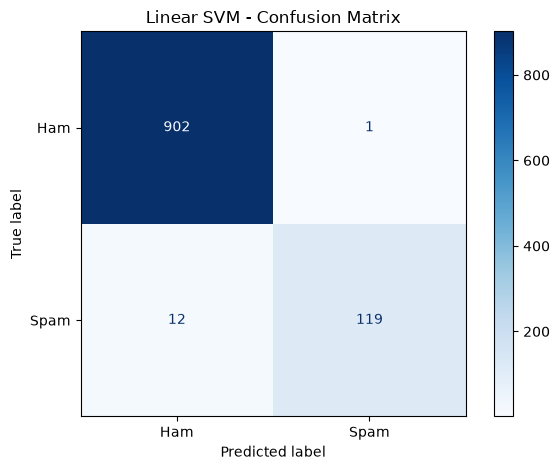

In [10]:

# STEP 16: Train Best Model and Evaluate

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Train best Linear SVM model
best_model = LinearSVC(
    C=5,
    random_state=42
)

best_model.fit(X_train_tfidf, y_train)

# Predictions on held-out test set
y_pred = best_model.predict(X_test_tfidf)

# Evaluation metrics
print("BEST MODEL: LINEAR SVM + TF-IDF")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, pos_label="spam"
))
print("Recall:", recall_score(
    y_test, y_pred, pos_label="spam"
))
print("F1 Score:", f1_score(
    y_test, y_pred, pos_label="spam"
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# Confusion Matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=["ham", "spam"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Linear SVM - Confusion Matrix")
plt.tight_layout()
plt.show()


In [11]:

# STEP 17: Threshold Optimization

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.svm import LinearSVC
from sklearn.metrics import confusion_matrix

# Split training data into training and validation
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train_tfidf,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

# Train SVM on sub-training data
threshold_model = LinearSVC(C=5, random_state=42)
threshold_model.fit(X_subtrain, y_subtrain)

# Get decision scores
val_scores = threshold_model.decision_function(X_val)

# Positive scores indicate spam
thresholds = np.unique(val_scores)

best_threshold = None
best_recall = -1
best_precision = 0
best_fpr = 1

for threshold in thresholds:
    predictions = np.where(
        val_scores >= threshold, "spam", "ham"
    )

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=["ham", "spam"]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) else 0
    recall = tp / (tp + fn) if (tp + fn) else 0
    precision = tp / (tp + fp) if (tp + fp) else 0

    if fpr <= 0.01 and (
        recall > best_recall or
        (recall == best_recall and precision > best_precision)
    ):
        best_threshold = threshold
        best_recall = recall
        best_precision = precision
        best_fpr = fpr

print("THRESHOLD OPTIMIZATION RESULTS")
print("--------------------------------")
print("Best Threshold:", best_threshold)
print("Validation Precision:", best_precision)
print("Validation Recall:", best_recall)
print("Validation False Positive Rate:", best_fpr)
 

THRESHOLD OPTIMIZATION RESULTS
--------------------------------
Best Threshold: -0.3178927748124507
Validation Precision: 0.9519230769230769
Validation Recall: 0.9519230769230769
Validation False Positive Rate: 0.006915629322268326


FINAL OPTIMIZED MODEL RESULTS
--------------------------------
Threshold: -0.3178927748124507
Accuracy: 0.9864603481624759
Precision: 0.9534883720930233
Recall: 0.9389312977099237
F1 Score: 0.9461538461538461

Classification Report:
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       903
        spam       0.95      0.94      0.95       131

    accuracy                           0.99      1034
   macro avg       0.97      0.97      0.97      1034
weighted avg       0.99      0.99      0.99      1034

True Negatives: 897
False Positives: 6
False Negatives: 8
True Positives: 123
Test False Positive Rate: 0.006644518272425249


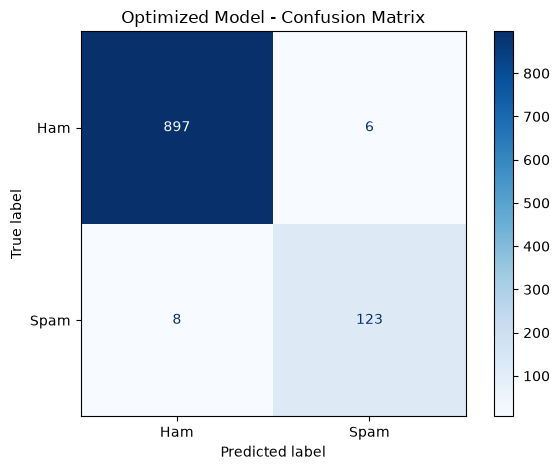

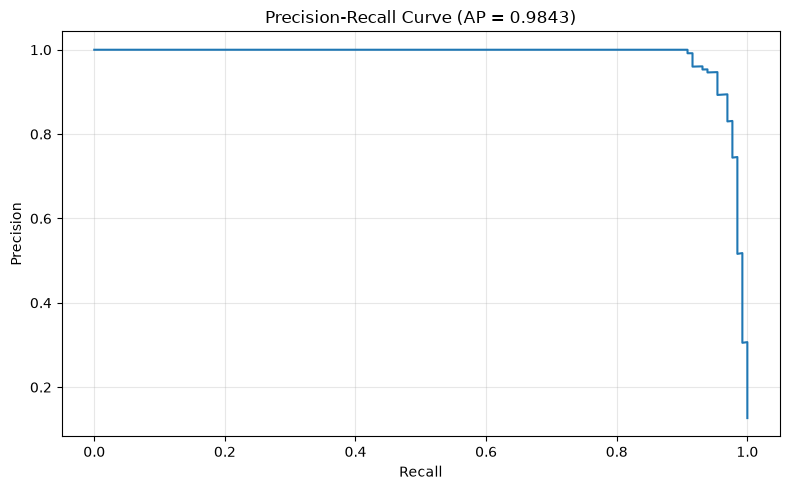

Average Precision: 0.9843453627387668


In [12]:

# STEP 18: Final Test Evaluation with Optimized Threshold

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score
)
import numpy as np
import matplotlib.pyplot as plt

# Predict using optimized threshold
test_scores = threshold_model.decision_function(X_test_tfidf)

y_test_pred = np.where(
    test_scores >= best_threshold,
    "spam",
    "ham"
)

# Final metrics
print("FINAL OPTIMIZED MODEL RESULTS")
print("--------------------------------")

print("Threshold:", best_threshold)

print("Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Precision:",
      precision_score(y_test, y_test_pred, pos_label="spam"))

print("Recall:",
      recall_score(y_test, y_test_pred, pos_label="spam"))

print("F1 Score:",
      f1_score(y_test, y_test_pred, pos_label="spam"))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=["ham", "spam"]
)

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

print("Test False Positive Rate:", fp / (fp + tn))

# Plot confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("Optimized Model - Confusion Matrix")
plt.tight_layout()
plt.show()

# Precision Recall Curve
precision_values, recall_values, thresholds = precision_recall_curve(
    (y_test == "spam").astype(int),
    test_scores
)

ap_score = average_precision_score(
    (y_test == "spam").astype(int),
    test_scores
)

plt.figure(figsize=(8, 5))
plt.plot(recall_values, precision_values)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(f"Precision-Recall Curve (AP = {ap_score:.4f})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Average Precision:", ap_score)


In [13]:

# STEP 19: Save Final Model and Vectorizer

import joblib
import os
import json

# Create models directory
os.makedirs("../models", exist_ok=True)

# Save trained model
joblib.dump(
    threshold_model,
    "../models/spam_detection_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf_vectorizer,
    "../models/tfidf_vectorizer.pkl"
)

# Save optimized threshold
with open("../models/threshold.json", "w") as f:
    json.dump(
        {"best_threshold": float(best_threshold)},
        f,
        indent=4
    )

print("MODEL SAVED SUCCESSFULLY!")
print("--------------------------------")
print("1. spam_detection_model.pkl")
print("2. tfidf_vectorizer.pkl")
print("3. threshold.json")
print("--------------------------------")
print("All files saved in models folder.")


MODEL SAVED SUCCESSFULLY!
--------------------------------
1. spam_detection_model.pkl
2. tfidf_vectorizer.pkl
3. threshold.json
--------------------------------
All files saved in models folder.


In [14]:

# STEP 20: Test Real SMS Messages

import joblib
import json

# Load saved model
model = joblib.load("../models/spam_detection_model.pkl")

# Load TF-IDF vectorizer
vectorizer = joblib.load("../models/tfidf_vectorizer.pkl")

# Load optimized threshold
with open("../models/threshold.json", "r") as f:
    threshold = json.load(f)["best_threshold"]

# Test messages
test_messages = [
    "Congratulations! You won a free iPhone. Claim now!",
    "Hey, are you coming to college tomorrow?",
    "URGENT! You have won 50000 cash. Call now!",
    "Let's meet at 5 PM today.",
    "FREE entry in a weekly competition. Text WIN now!"
]

# Make predictions
X_new = vectorizer.transform(test_messages)
scores = model.decision_function(X_new)

predictions = (scores >= threshold).astype(int)

# Display results
for message, prediction in zip(test_messages, predictions):
    result = "SPAM" if prediction == 1 else "HAM"

    print("\nMessage:", message)
    print("Prediction:", result)
    print("-" * 60)



Message: Congratulations! You won a free iPhone. Claim now!
Prediction: SPAM
------------------------------------------------------------

Message: Hey, are you coming to college tomorrow?
Prediction: HAM
------------------------------------------------------------

Message: URGENT! You have won 50000 cash. Call now!
Prediction: SPAM
------------------------------------------------------------

Message: Let's meet at 5 PM today.
Prediction: HAM
------------------------------------------------------------

Message: FREE entry in a weekly competition. Text WIN now!
Prediction: SPAM
------------------------------------------------------------



# SMS Spam Message Detection Using Machine Learning

## 1. Project Overview
This project detects whether an SMS message is Spam or Ham using Machine Learning.

## 2. Dataset
- Dataset: SMS Spam Collection
- Original Records: 5572
- Records after duplicate removal: 5169
- Features: Label and Message

## 3. Data Preprocessing
- Duplicate removal
- Text cleaning
- Lowercase conversion
- Stopword removal
- Train-test splitting

## 4. Feature Extraction
- Bag of Words
- TF-IDF Vectorization

## 5. Machine Learning Algorithms
- Naive Bayes
- Logistic Regression
- Linear Support Vector Machine

## 6. Best Model
Linear SVM with TF-IDF and optimized threshold.

## 7. Final Performance
- Accuracy: 98.64%
- Precision: 95.35%
- Recall: 93.89%
- F1 Score: 94.62%

## 8. Conclusion
The optimized Linear SVM model successfully
classifies SMS messages into Spam and Ham categories.
